# 06 — Statistical Significance of Forecasting Differences

Split from `WindForecasting.ipynb`. Diebold–Mariano tests with the Harvey–Leybourne–Newbold small-sample correction (overall and per horizon), Holm-adjusted $p$-values, and dependence-aware comparisons for all planned model pairs. Results are written to `data/optimization_output/forecast_significance/`.

**Prerequisite:** run the save cells at the end of notebooks 02, 03, 04, and 05 (or run those notebooks fully) so the prediction arrays exist in `data/processed/forecast_predictions/`.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from rich.jupyter import display

# ============================================================
# PROJECT PATHS
# ============================================================

CURRENT_DIR = Path.cwd()

# Walk upward until a folder containing the raw wind dataset is found,
# so this notebook works from Data/Microgrid-Forecasting-Stochastic-
# Optimization/notebooks as well as from Data/notebooks. If the raw
# data is later copied into this repository's data/raw, the repository
# root is used automatically.
_candidates = [CURRENT_DIR, *CURRENT_DIR.parents]
PROJECT_ROOT = None
for candidate in _candidates:
    if (candidate / "data" / "raw" / "agregatenew.csv").exists():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    # GitHub clone: raw data absent, derived inputs distributed
    for candidate in _candidates:
        if (candidate / "data" / "optimization_input"
                / "pgu_parameters.csv").exists():
            PROJECT_ROOT = candidate
            break
if PROJECT_ROOT is None:
    PROJECT_ROOT = CURRENT_DIR

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OPT_INPUT_DIR = PROJECT_ROOT / "data" / "optimization_input"
OPT_OUTPUT_DIR = PROJECT_ROOT / "data" / "optimization_output"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data: {RAW_DIR}")

Project root: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data
Raw data: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/raw


In [ ]:
# ============================================================
# LOAD SAVED TEST-SET PREDICTIONS
# Produced by notebooks 02-05 (save cells at the end of each).
# Skip this cell if the arrays are already in memory because
# the model notebooks were run in this kernel.
# ============================================================

import numpy as np

PRED_DIR = PROCESSED_DIR / "forecast_predictions"

y_test_original = np.load(PRED_DIR / "y_test.npy")
persistence_original = np.load(PRED_DIR / "persistence.npy")
seasonal_persistence_original = np.load(
    PRED_DIR / "seasonal_persistence.npy"
)
cnn_lstm_v2_pred = np.load(PRED_DIR / "cnn_lstm_v2.npy")
patchtst_predictions = np.load(PRED_DIR / "patchtst.npy")
chronos_point_predictions = np.load(PRED_DIR / "chronos_p50.npy")

print("Loaded prediction matrices:", y_test_original.shape)

In [160]:
from __future__ import annotations

from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import t as student_t

In [161]:
# ============================================================
# STATISTICAL SIGNIFICANCE: DATA PREPARATION
# ============================================================

SIGNIFICANCE_DIR = (
    OPT_OUTPUT_DIR
    / "forecast_significance"
)

SIGNIFICANCE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def as_forecast_matrix(
    values,
    name: str,
    expected_shape: tuple[int, int],
) -> np.ndarray:
    """
    Convert a forecast array to an N x H matrix and verify that
    it matches the observed test-set shape.
    """

    array = np.asarray(
        values,
        dtype=float,
    )

    # Remove trailing singleton dimensions if present.
    array = np.squeeze(array)

    if array.shape == expected_shape:
        return array

    # Handle a transposed H x N matrix.
    if array.shape == (
        expected_shape[1],
        expected_shape[0],
    ):
        return array.T

    raise ValueError(
        f"{name} has shape {array.shape}; "
        f"expected {expected_shape}."
    )


actual_matrix = np.asarray(
    y_test_original,
    dtype=float,
)

actual_matrix = np.squeeze(
    actual_matrix
)

if actual_matrix.ndim != 2:
    raise ValueError(
        "y_test_original must be an N x 24 matrix. "
        f"Received shape: {actual_matrix.shape}"
    )

expected_shape = actual_matrix.shape

if expected_shape[1] != 24:
    raise ValueError(
        "The test targets must contain 24 forecast horizons. "
        f"Received shape: {expected_shape}"
    )


forecast_matrices = {
    "Constant Persistence": as_forecast_matrix(
        persistence_original,
        "persistence_original",
        expected_shape,
    ),

    "Seasonal Persistence": as_forecast_matrix(
        seasonal_persistence_original,
        "seasonal_persistence_original",
        expected_shape,
    ),

    "CNN-LSTM V2": as_forecast_matrix(
        cnn_lstm_v2_pred,
        "cnn_lstm_v2_pred",
        expected_shape,
    ),

    "PatchTST": as_forecast_matrix(
        patchtst_predictions,
        "patchtst_predictions",
        expected_shape,
    ),

    "Chronos-2": as_forecast_matrix(
        chronos_point_predictions,
        "chronos_point_predictions",
        expected_shape,
    ),
}


if not np.isfinite(
    actual_matrix
).all():
    raise ValueError(
        "The observed test matrix contains NaN or infinite values."
    )

for model_name, forecast_matrix in forecast_matrices.items():

    if not np.isfinite(
        forecast_matrix
    ).all():
        raise ValueError(
            f"{model_name} predictions contain NaN or infinite values."
        )


print("Observed test shape:", actual_matrix.shape)

for model_name, forecast_matrix in forecast_matrices.items():
    print(
        f"{model_name:24s}",
        forecast_matrix.shape,
    )

Observed test shape: (1234, 24)
Constant Persistence     (1234, 24)
Seasonal Persistence     (1234, 24)
CNN-LSTM V2              (1234, 24)
PatchTST                 (1234, 24)
Chronos-2                (1234, 24)


In [162]:
# ============================================================
# DIEBOLD-MARIANO TEST
# ============================================================

def calculate_loss(
    actual: np.ndarray,
    forecast: np.ndarray,
    loss: str,
) -> np.ndarray:
    """
    Calculate element-wise forecast losses.

    loss="absolute" evaluates MAE-based accuracy.
    loss="squared" evaluates MSE/RMSE-based accuracy.
    """

    error = (
        actual
        - forecast
    )

    if loss == "absolute":
        return np.abs(error)

    if loss == "squared":
        return np.square(error)

    raise ValueError(
        "loss must be either 'absolute' or 'squared'."
    )


def newey_west_long_run_variance(
    values: np.ndarray,
    max_lag: int,
) -> float:
    """
    Estimate the long-run variance of a loss-differential
    series using Bartlett/Newey-West weights.
    """

    values = np.asarray(
        values,
        dtype=float,
    ).reshape(-1)

    n_observations = len(values)

    if n_observations < 3:
        raise ValueError(
            "At least three observations are required."
        )

    max_lag = int(
        min(
            max(max_lag, 0),
            n_observations - 1,
        )
    )

    centered = (
        values
        - values.mean()
    )

    gamma_zero = float(
        np.dot(
            centered,
            centered,
        )
        / n_observations
    )

    long_run_variance = gamma_zero

    for lag in range(
        1,
        max_lag + 1,
    ):

        autocovariance = float(
            np.dot(
                centered[lag:],
                centered[:-lag],
            )
            / n_observations
        )

        bartlett_weight = (
            1.0
            - lag
            / (
                max_lag + 1.0
            )
        )

        long_run_variance += (
            2.0
            * bartlett_weight
            * autocovariance
        )

    return float(
        max(
            long_run_variance,
            0.0,
        )
    )


def diebold_mariano_test(
    actual: np.ndarray,
    forecast_a: np.ndarray,
    forecast_b: np.ndarray,
    *,
    loss: str = "absolute",
    forecast_horizon: int = 1,
    max_lag: int | None = None,
    apply_hln_correction: bool = True,
) -> dict[str, float | str | bool]:
    """
    Two-sided Diebold-M ariano test.

    The loss differential is:

        d_t = loss_A,t - loss_B,t

    Therefore:
      mean_loss_difference < 0  -> Model A has lower loss
      mean_loss_difference > 0  -> Model B has lower loss
    """

    actual = np.asarray(
        actual,
        dtype=float,
    ).reshape(-1)

    forecast_a = np.asarray(
        forecast_a,
        dtype=float,
    ).reshape(-1)

    forecast_b = np.asarray(
        forecast_b,
        dtype=float,
    ).reshape(-1)

    if not (
        len(actual)
        == len(forecast_a)
        == len(forecast_b)
    ):
        raise ValueError(
            "Actual and forecast arrays must have equal lengths."
        )

    valid_mask = (
        np.isfinite(actual)
        & np.isfinite(forecast_a)
        & np.isfinite(forecast_b)
    )

    actual = actual[
        valid_mask
    ]

    forecast_a = forecast_a[
        valid_mask
    ]

    forecast_b = forecast_b[
        valid_mask
    ]

    n_observations = len(actual)

    if n_observations < 10:
        raise ValueError(
            "Too few valid observations for a reliable DM test."
        )

    loss_a = calculate_loss(
        actual,
        forecast_a,
        loss,
    )

    loss_b = calculate_loss(
        actual,
        forecast_b,
        loss,
    )

    loss_difference = (
        loss_a
        - loss_b
    )

    mean_difference = float(
        loss_difference.mean()
    )

    if max_lag is None:
        max_lag = max(
            int(forecast_horizon) - 1,
            0,
        )

    long_run_variance = (
        newey_west_long_run_variance(
            loss_difference,
            max_lag=max_lag,
        )
    )

    if long_run_variance <= 1e-15:

        if abs(
            mean_difference
        ) <= 1e-15:
            dm_statistic = 0.0
            p_value = 1.0
        else:
            dm_statistic = (
                np.sign(
                    mean_difference
                )
                * np.inf
            )
            p_value = 0.0

    else:

        standard_error = np.sqrt(
            long_run_variance
            / n_observations
        )

        dm_statistic = (
            mean_difference
            / standard_error
        )

        if apply_hln_correction:

            h = min(
                max(
                    int(forecast_horizon),
                    1,
                ),
                n_observations,
            )

            correction_term = (
                n_observations
                + 1
                - 2 * h
                + (
                    h
                    * (h - 1)
                    / n_observations
                )
            ) / n_observations

            if correction_term > 0:
                dm_statistic *= np.sqrt(
                    correction_term
                )

        p_value = float(
            2.0
            * student_t.sf(
                abs(dm_statistic),
                df=n_observations - 1,
            )
        )

    if mean_difference < 0:
        better_model = "Model A"
    elif mean_difference > 0:
        better_model = "Model B"
    else:
        better_model = "Tie"

    return {
        "n_observations":
            n_observations,

        "forecast_horizon":
            int(forecast_horizon),

        "max_lag":
            int(max_lag),

        "loss":
            loss,

        "mean_loss_a":
            float(
                loss_a.mean()
            ),

        "mean_loss_b":
            float(
                loss_b.mean()
            ),

        "mean_loss_difference_a_minus_b":
            mean_difference,

        "dm_statistic":
            float(dm_statistic),

        "p_value":
            p_value,

        "better_position":
            better_model,
    }

In [163]:
# ============================================================
# PLANNED MODEL COMPARISONS
# ============================================================

planned_comparisons = [
    (
        "CNN-LSTM V2",
        "PatchTST",
    ),
    (
        "CNN-LSTM V2",
        "Chronos-2",
    ),
    (
        "PatchTST",
        "Chronos-2",
    ),
    (
        "Chronos-2",
        "Constant Persistence",
    ),
    (
        "PatchTST",
        "Constant Persistence",
    ),
    (
        "CNN-LSTM V2",
        "Constant Persistence",
    ),
    (
        "Seasonal Persistence",
        "Constant Persistence",
    ),
]

In [164]:
# ============================================================
# OVERALL DM TEST
# ============================================================

def run_overall_dm_tests(
    actual: np.ndarray,
    forecasts: dict[str, np.ndarray],
    comparisons: list[tuple[str, str]],
    loss: str = "absolute",
) -> pd.DataFrame:
    """
    Run trajectory-level overall DM tests.

    Each statistical observation is one forecast origin.
    The loss at that origin is averaged across the 24 lead
    times before the DM test is performed.
    """

    result_rows = []

    if loss == "absolute":
        actual_loss_name = "MAE"
    else:
        actual_loss_name = "MSE"

    for model_a, model_b in comparisons:

        forecast_a = forecasts[
            model_a
        ]

        forecast_b = forecasts[
            model_b
        ]

        origin_loss_a = calculate_loss(
            actual,
            forecast_a,
            loss,
        ).mean(axis=1)

        origin_loss_b = calculate_loss(
            actual,
            forecast_b,
            loss,
        ).mean(axis=1)

        # Create pseudo-actual zeros so the generic DM function
        # compares the already-calculated origin-level losses.
        dm_result = diebold_mariano_test(
            actual=np.zeros_like(
                origin_loss_a
            ),
            forecast_a=origin_loss_a,
            forecast_b=origin_loss_b,
            loss="absolute",
            forecast_horizon=24,
            max_lag=23,
            apply_hln_correction=True,
        )

        mean_difference = float(
            origin_loss_a.mean()
            - origin_loss_b.mean()
        )

        if mean_difference < 0:
            better_model = model_a
        elif mean_difference > 0:
            better_model = model_b
        else:
            better_model = "Tie"

        result_rows.append(
            {
                "model_a":
                    model_a,

                "model_b":
                    model_b,

                "evaluation_loss":
                    actual_loss_name,

                "mean_loss_model_a":
                    float(
                        origin_loss_a.mean()
                    ),

                "mean_loss_model_b":
                    float(
                        origin_loss_b.mean()
                    ),

                "loss_difference_a_minus_b":
                    mean_difference,

                "dm_statistic":
                    dm_result[
                        "dm_statistic"
                    ],

                "p_value":
                    dm_result[
                        "p_value"
                    ],

                "significant_0_05":
                    dm_result[
                        "p_value"
                    ] < 0.05,

                "better_model":
                    better_model,

                "n_forecast_origins":
                    len(origin_loss_a),

                "hac_max_lag":
                    23,
            }
        )

    return pd.DataFrame(
        result_rows
    )


overall_dm_absolute_df = (
    run_overall_dm_tests(
        actual_matrix,
        forecast_matrices,
        planned_comparisons,
        loss="absolute",
    )
)

overall_dm_squared_df = (
    run_overall_dm_tests(
        actual_matrix,
        forecast_matrices,
        planned_comparisons,
        loss="squared",
    )
)

overall_dm_df = pd.concat(
    [
        overall_dm_absolute_df,
        overall_dm_squared_df,
    ],
    ignore_index=True,
)

overall_dm_df.to_csv(
    SIGNIFICANCE_DIR
    / "dm_overall_results.csv",
    index=False,
)

display(
    overall_dm_df.round(5)
)

,model_a,model_b,evaluation_loss,mean_loss_model_a,mean_loss_model_b,loss_difference_a_minus_b,dm_statistic,p_value,significant_0_05,better_model,n_forecast_origins,hac_max_lag
0,CNN-LSTM V2,PatchTST,MAE,2.78376,2.98232,-0.19856,-2.73781,0.00627,True,CNN-LSTM V2,1234,23
1,CNN-LSTM V2,Chronos-2,MAE,2.78376,2.84575,-0.06199,-0.45289,0.65071,False,CNN-LSTM V2,1234,23
2,PatchTST,Chronos-2,MAE,2.98232,2.84575,0.13657,0.93873,0.34805,False,Chronos-2,1234,23
3,Chronos-2,Constant Persistence,MAE,2.84575,3.12112,-0.27537,-2.89661,0.00384,True,Chronos-2,1234,23
4,PatchTST,Constant Persistence,MAE,2.98232,3.12112,-0.13880,-0.77731,0.43712,False,PatchTST,1234,23
5,CNN-LSTM V2,Constant Persistence,MAE,2.78376,3.12112,-0.33737,-1.99844,0.04589,True,CNN-LSTM V2,1234,23
6,Seasonal Persistence,Constant Persistence,MAE,3.99767,3.12112,0.87655,5.50001,0.00000,True,Constant Persistence,1234,23
7,CNN-LSTM V2,PatchTST,MSE,12.24141,14.21981,-1.97840,-3.32683,0.00090,True,CNN-LSTM V2,1234,23
8,CNN-LSTM V2,Chronos-2,MSE,12.24141,14.73537,-2.49397,-2.10469,0.03552,True,CNN-LSTM V2,1234,23
9,PatchTST,Chronos-2,MSE,14.21981,14.73537,-0.51557,-0.40100,0.68849,False,PatchTST,1234,23


In [165]:
# ============================================================
# HORIZON-WISE DM TESTS
# ============================================================

def run_horizon_dm_tests(
    actual: np.ndarray,
    forecasts: dict[str, np.ndarray],
    comparisons: list[tuple[str, str]],
    loss: str = "absolute",
) -> pd.DataFrame:

    result_rows = []

    for model_a, model_b in comparisons:

        forecast_a = forecasts[
            model_a
        ]

        forecast_b = forecasts[
            model_b
        ]

        for horizon_index in range(
            actual.shape[1]
        ):

            lead_time = (
                horizon_index + 1
            )

            dm_result = (
                diebold_mariano_test(
                    actual=actual[
                        :,
                        horizon_index,
                    ],

                    forecast_a=forecast_a[
                        :,
                        horizon_index,
                    ],

                    forecast_b=forecast_b[
                        :,
                        horizon_index,
                    ],

                    loss=loss,

                    forecast_horizon=lead_time,

                    max_lag=max(
                        lead_time - 1,
                        0,
                    ),

                    apply_hln_correction=True,
                )
            )

            mean_difference = (
                dm_result[
                    "mean_loss_difference_a_minus_b"
                ]
            )

            if mean_difference < 0:
                better_model = model_a
            elif mean_difference > 0:
                better_model = model_b
            else:
                better_model = "Tie"

            result_rows.append(
                {
                    "model_a":
                        model_a,

                    "model_b":
                        model_b,

                    "horizon":
                        lead_time,

                    "loss":
                        loss,

                    "mean_loss_model_a":
                        dm_result[
                            "mean_loss_a"
                        ],

                    "mean_loss_model_b":
                        dm_result[
                            "mean_loss_b"
                        ],

                    "loss_difference_a_minus_b":
                        mean_difference,

                    "dm_statistic":
                        dm_result[
                            "dm_statistic"
                        ],

                    "p_value":
                        dm_result[
                            "p_value"
                        ],

                    "significant_unadjusted_0_05":
                        dm_result[
                            "p_value"
                        ] < 0.05,

                    "better_model":
                        better_model,

                    "n_observations":
                        dm_result[
                            "n_observations"
                        ],

                    "hac_max_lag":
                        dm_result[
                            "max_lag"
                        ],
                }
            )

    return pd.DataFrame(
        result_rows
    )


horizon_dm_absolute_df = (
    run_horizon_dm_tests(
        actual_matrix,
        forecast_matrices,
        planned_comparisons,
        loss="absolute",
    )
)

horizon_dm_squared_df = (
    run_horizon_dm_tests(
        actual_matrix,
        forecast_matrices,
        planned_comparisons,
        loss="squared",
    )
)

horizon_dm_df = pd.concat(
    [
        horizon_dm_absolute_df,
        horizon_dm_squared_df,
    ],
    ignore_index=True,
)

In [166]:
# ============================================================
# HOLM MULTIPLE-TESTING CORRECTION
# ============================================================

def holm_adjust_p_values(
    p_values: np.ndarray,
) -> np.ndarray:
    """
    Holm step-down family-wise error correction.
    """

    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    number_of_tests = len(
        p_values
    )

    order = np.argsort(
        p_values
    )

    ordered_p_values = p_values[
        order
    ]

    adjusted_ordered = np.empty(
        number_of_tests,
        dtype=float,
    )

    running_maximum = 0.0

    for rank, p_value in enumerate(
        ordered_p_values
    ):

        multiplier = (
            number_of_tests
            - rank
        )

        adjusted_value = min(
            multiplier
            * p_value,
            1.0,
        )

        running_maximum = max(
            running_maximum,
            adjusted_value,
        )

        adjusted_ordered[
            rank
        ] = running_maximum

    adjusted = np.empty(
        number_of_tests,
        dtype=float,
    )

    adjusted[
        order
    ] = adjusted_ordered

    return adjusted


horizon_dm_df[
    "p_value_holm"
] = np.nan

for (
    model_a,
    model_b,
    loss_name
), group_indices in horizon_dm_df.groupby(
    [
        "model_a",
        "model_b",
        "loss",
    ]
).groups.items():

    p_values = horizon_dm_df.loc[
        group_indices,
        "p_value",
    ].to_numpy(dtype=float)

    horizon_dm_df.loc[
        group_indices,
        "p_value_holm",
    ] = holm_adjust_p_values(
        p_values
    )


horizon_dm_df[
    "significant_holm_0_05"
] = (
    horizon_dm_df[
        "p_value_holm"
    ]
    < 0.05
)


horizon_dm_df.to_csv(
    SIGNIFICANCE_DIR
    / "dm_horizon_results.csv",
    index=False,
)

display(
    horizon_dm_df[
        horizon_dm_df[
            "horizon"
        ].isin(
            [1, 6, 12, 18, 24]
        )
    ].round(5)
)

,model_a,model_b,horizon,loss,mean_loss_model_a,mean_loss_model_b,loss_difference_a_minus_b,dm_statistic,p_value,significant_unadjusted_0_05,better_model,n_observations,hac_max_lag,p_value_holm,significant_holm_0_05
0,CNN-LSTM V2,PatchTST,1,absolute,1.50701,1.38739,0.11962,3.48400,0.00051,True,PatchTST,1234,0,0.00971,True
5,CNN-LSTM V2,PatchTST,6,absolute,2.49561,2.62163,-0.12602,-2.06130,0.03948,True,CNN-LSTM V2,1234,5,0.11845,False
11,CNN-LSTM V2,PatchTST,12,absolute,2.92774,3.32472,-0.39698,-4.15081,0.00004,True,CNN-LSTM V2,1234,11,0.00085,True
17,CNN-LSTM V2,PatchTST,18,absolute,3.10293,3.40692,-0.30399,-3.03058,0.00249,True,CNN-LSTM V2,1234,17,0.03488,True
23,CNN-LSTM V2,PatchTST,24,absolute,3.16640,3.45923,-0.29283,-3.61757,0.00031,True,CNN-LSTM V2,1234,23,0.00650,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
312,Seasonal Persistence,Constant Persistence,1,squared,26.15303,1.89246,24.26057,22.04201,0.00000,True,Constant Persistence,1234,0,0.00000,True
317,Seasonal Persistence,Constant Persistence,6,squared,26.41008,12.10997,14.30011,6.19813,0.00000,True,Constant Persistence,1234,5,0.00000,True
323,Seasonal Persistence,Constant Persistence,12,squared,26.47245,18.30193,8.17052,3.13984,0.00173,True,Constant Persistence,1234,11,0.01940,True
329,Seasonal Persistence,Constant Persistence,18,squared,26.72539,23.06308,3.66231,2.19852,0.02810,True,Constant Persistence,1234,17,0.12302,False


In [167]:
# ============================================================
# MANUSCRIPT TABLE
# ============================================================

selected_reporting_horizons = [
    1,
    6,
    12,
    24,
]

main_horizon_dm_table = (
    horizon_dm_df[
        (
            horizon_dm_df[
                "loss"
            ]
            == "absolute"
        )
        &
        (
            horizon_dm_df[
                "horizon"
            ].isin(
                selected_reporting_horizons
            )
        )
    ]
    [
        [
            "model_a",
            "model_b",
            "horizon",
            "loss_difference_a_minus_b",
            "dm_statistic",
            "p_value",
            "p_value_holm",
            "significant_holm_0_05",
            "better_model",
        ]
    ]
    .copy()
)


main_horizon_dm_table[
    "comparison"
] = (
    main_horizon_dm_table[
        "model_a"
    ]
    + " vs. "
    + main_horizon_dm_table[
        "model_b"
    ]
)

main_horizon_dm_table = (
    main_horizon_dm_table[
        [
            "comparison",
            "horizon",
            "loss_difference_a_minus_b",
            "dm_statistic",
            "p_value",
            "p_value_holm",
            "significant_holm_0_05",
            "better_model",
        ]
    ]
    .sort_values(
        [
            "comparison",
            "horizon",
        ]
    )
)


main_horizon_dm_table.to_csv(
    SIGNIFICANCE_DIR
    / "dm_main_manuscript_table.csv",
    index=False,
)


main_horizon_dm_table.to_latex(
    SIGNIFICANCE_DIR
    / "dm_main_manuscript_table.tex",
    index=False,
    float_format="%.4f",
    caption=(
        "Horizon-wise Diebold--Mariano tests using "
        "absolute-error loss. Negative loss differences "
        "indicate lower error for the first model. "
        "Holm-adjusted p-values account for testing across "
        "the 24 forecast horizons."
    ),
    label="tab:dm_horizon",
)


display(
    main_horizon_dm_table.round(5)
)


,comparison,horizon,loss_difference_a_minus_b,dm_statistic,p_value,p_value_holm,significant_holm_0_05,better_model
24,CNN-LSTM V2 vs. Chronos-2,1,0.46216,14.04676,0.00000,0.00000,True,Chronos-2
29,CNN-LSTM V2 vs. Chronos-2,6,-0.09795,-1.02098,0.30746,1.00000,False,CNN-LSTM V2
35,CNN-LSTM V2 vs. Chronos-2,12,-0.04743,-0.29518,0.76790,1.00000,False,CNN-LSTM V2
47,CNN-LSTM V2 vs. Chronos-2,24,-0.31420,-1.77322,0.07644,1.00000,False,CNN-LSTM V2
120,CNN-LSTM V2 vs. Constant Persistence,1,0.47706,14.23372,0.00000,0.00000,True,Constant Persistence
125,CNN-LSTM V2 vs. Constant Persistence,6,-0.18278,-1.72482,0.08481,0.56246,False,CNN-LSTM V2
131,CNN-LSTM V2 vs. Constant Persistence,12,-0.36278,-1.87052,0.06165,0.56246,False,CNN-LSTM V2
143,CNN-LSTM V2 vs. Constant Persistence,24,-0.84772,-3.41235,0.00066,0.01463,True,CNN-LSTM V2
0,CNN-LSTM V2 vs. PatchTST,1,0.11962,3.48400,0.00051,0.00971,True,PatchTST
5,CNN-LSTM V2 vs. PatchTST,6,-0.12602,-2.06130,0.03948,0.11845,False,CNN-LSTM V2


In [168]:
# ============================================================
# SIGNIFICANCE SUMMARY
# ============================================================

absolute_horizon_results = (
    horizon_dm_df[
        horizon_dm_df[
            "loss"
        ]
        == "absolute"
    ]
    .copy()
)


summary_rows = []

for (
    model_a,
    model_b
), group in absolute_horizon_results.groupby(
    [
        "model_a",
        "model_b",
    ]
):

    significant_group = group[
        group[
            "significant_holm_0_05"
        ]
    ]

    a_wins = int(
        (
            significant_group[
                "better_model"
            ]
            == model_a
        ).sum()
    )

    b_wins = int(
        (
            significant_group[
                "better_model"
            ]
            == model_b
        ).sum()
    )

    nonsignificant = (
        24
        - a_wins
        - b_wins
    )

    summary_rows.append(
        {
            "model_a":
                model_a,

            "model_b":
                model_b,

            "significant_horizons_model_a_better":
                a_wins,

            "significant_horizons_model_b_better":
                b_wins,

            "nonsignificant_horizons":
                nonsignificant,

            "horizons_model_a_significantly_better":
                ", ".join(
                    map(
                        str,
                        significant_group.loc[
                            significant_group[
                                "better_model"
                            ]
                            == model_a,
                            "horizon",
                        ].tolist(),
                    )
                ),

            "horizons_model_b_significantly_better":
                ", ".join(
                    map(
                        str,
                        significant_group.loc[
                            significant_group[
                                "better_model"
                            ]
                            == model_b,
                            "horizon",
                        ].tolist(),
                    )
                ),
        }
    )


dm_significance_summary_df = pd.DataFrame(
    summary_rows
)


dm_significance_summary_df.to_csv(
    SIGNIFICANCE_DIR
    / "dm_significant_horizon_summary.csv",
    index=False,
)


display(
    dm_significance_summary_df
)

,model_a,model_b,significant_horizons_model_a_better,significant_horizons_model_b_better,nonsignificant_horizons,horizons_model_a_significantly_better,horizons_model_b_significantly_better
0,CNN-LSTM V2,Chronos-2,0,3,21,,"1, 2, 3"
1,CNN-LSTM V2,Constant Persistence,1,3,20,24,"1, 2, 3"
2,CNN-LSTM V2,PatchTST,14,3,7,"9, 10, 11, 12, 13, 14, 15, 16, 18, 19, 21, 22,...","1, 2, 3"
3,Chronos-2,Constant Persistence,0,0,24,,
4,PatchTST,Chronos-2,0,2,22,,"1, 2"
5,PatchTST,Constant Persistence,0,2,22,,"1, 2"
6,Seasonal Persistence,Constant Persistence,0,13,11,,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13"


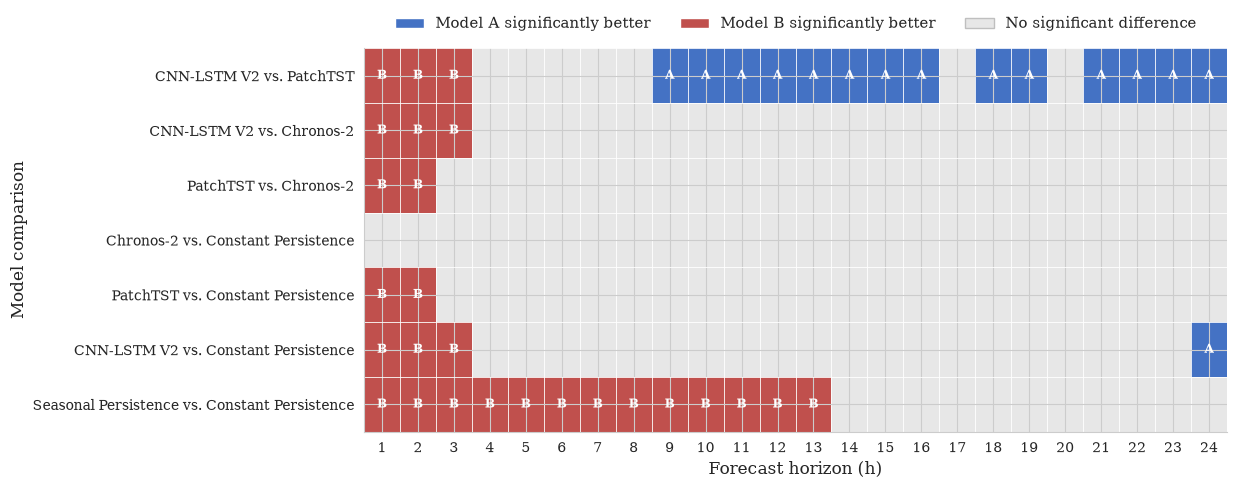

Saved:
/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/figures/dm_horizon_significance.pdf
/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/figures/dm_horizon_significance.png


In [169]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch


# ============================================================
# PREPARE HORIZON-WISE SIGNIFICANCE MATRIX
# ============================================================

required_columns = {
    "model_a",
    "model_b",
    "horizon",
    "better_model",
    "p_value_holm",
    "significant_holm_0_05",
}

missing_columns = (
    required_columns
    - set(horizon_dm_df.columns)
)

if missing_columns:
    raise ValueError(
        "horizon_dm_df is missing required columns: "
        f"{sorted(missing_columns)}"
    )


# Use absolute-error results only.
plot_dm_df = (
    horizon_dm_df[
        horizon_dm_df["loss"]
        == "absolute"
    ]
    .copy()
)

plot_dm_df["comparison"] = (
    plot_dm_df["model_a"]
    + " vs. "
    + plot_dm_df["model_b"]
)


# Preserve the planned comparison order.
comparison_order = [
    f"{model_a} vs. {model_b}"
    for model_a, model_b
    in planned_comparisons
]

plot_dm_df["comparison"] = pd.Categorical(
    plot_dm_df["comparison"],
    categories=comparison_order,
    ordered=True,
)

plot_dm_df = plot_dm_df.sort_values(
    ["comparison", "horizon"]
)


# ============================================================
# ENCODE RESULTS
# ============================================================
# -1 = Model A significantly better
#  0 = No significant difference
# +1 = Model B significantly better
# ============================================================

significance_matrix = np.zeros(
    (
        len(comparison_order),
        24,
    ),
    dtype=int,
)

adjusted_p_matrix = np.full(
    (
        len(comparison_order),
        24,
    ),
    np.nan,
    dtype=float,
)


for row_index, comparison in enumerate(
    comparison_order
):

    comparison_df = plot_dm_df[
        plot_dm_df["comparison"]
        == comparison
    ]

    if len(comparison_df) != 24:
        raise ValueError(
            f"{comparison} has "
            f"{len(comparison_df)} horizons; "
            "expected 24."
        )

    model_a = comparison_df[
        "model_a"
    ].iloc[0]

    model_b = comparison_df[
        "model_b"
    ].iloc[0]

    for _, row in comparison_df.iterrows():

        column_index = (
            int(row["horizon"])
            - 1
        )

        adjusted_p_matrix[
            row_index,
            column_index,
        ] = row["p_value_holm"]

        if not bool(
            row["significant_holm_0_05"]
        ):
            significance_matrix[
                row_index,
                column_index,
            ] = 0

        elif row["better_model"] == model_a:
            significance_matrix[
                row_index,
                column_index,
            ] = -1

        elif row["better_model"] == model_b:
            significance_matrix[
                row_index,
                column_index,
            ] = 1

        else:
            raise ValueError(
                "A significant result does not identify "
                "Model A or Model B as the better model."
            )


# ============================================================
# PUBLICATION STYLE
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 11,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "axes.linewidth": 0.8,
        "savefig.dpi": 600,
    }
)


# ============================================================
# COLOR MAP
# ============================================================

color_map = ListedColormap(
    [
        "#4472C4",  # Model A better
        "#E7E7E7",  # No significant difference
        "#C0504D",  # Model B better
    ]
)

normalization = BoundaryNorm(
    [
        -1.5,
        -0.5,
        0.5,
        1.5,
    ],
    color_map.N,
)


# ============================================================
# PLOT
# ============================================================

figure_height = max(
    3.8,
    0.55 * len(comparison_order)
    + 1.6,
)

fig, ax = plt.subplots(
    figsize=(12.5, figure_height)
)

image = ax.imshow(
    significance_matrix,
    cmap=color_map,
    norm=normalization,
    aspect="auto",
    interpolation="nearest",
)


# Major ticks.
ax.set_xticks(
    np.arange(24)
)

ax.set_xticklabels(
    np.arange(1, 25)
)

ax.set_yticks(
    np.arange(
        len(comparison_order)
    )
)

ax.set_yticklabels(
    comparison_order
)

ax.set_xlabel(
    "Forecast horizon (h)"
)

ax.set_ylabel(
    "Model comparison"
)


# Cell boundaries.
ax.set_xticks(
    np.arange(-0.5, 24, 1),
    minor=True,
)

ax.set_yticks(
    np.arange(
        -0.5,
        len(comparison_order),
        1,
    ),
    minor=True,
)

ax.grid(
    which="minor",
    linewidth=0.6,
    color="white",
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False,
)


# Add symbols to significant cells.
for row_index in range(
    significance_matrix.shape[0]
):
    for column_index in range(
        significance_matrix.shape[1]
    ):

        result_code = significance_matrix[
            row_index,
            column_index,
        ]

        if result_code == -1:
            symbol = "A"

        elif result_code == 1:
            symbol = "B"

        else:
            symbol = ""

        if symbol:
            ax.text(
                column_index,
                row_index,
                symbol,
                ha="center",
                va="center",
                fontsize=8.5,
                fontweight="bold",
                color="white",
            )


# Remove unnecessary borders.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# Legend.
legend_elements = [
    Patch(
        facecolor="#4472C4",
        label="Model A significantly better",
    ),
    Patch(
        facecolor="#C0504D",
        label="Model B significantly better",
    ),
    Patch(
        facecolor="#E7E7E7",
        edgecolor="0.75",
        label="No significant difference",
    ),
]

ax.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=False,
)


fig.tight_layout(
    rect=[0, 0, 1, 0.92]
)


# ============================================================
# SAVE
# ============================================================

dm_figure_pdf = (
    FIGURES_DIR
    / "dm_horizon_significance.pdf"
)

dm_figure_png = (
    FIGURES_DIR
    / "dm_horizon_significance.png"
)

fig.savefig(
    dm_figure_pdf,
    bbox_inches="tight",
)

fig.savefig(
    dm_figure_png,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(dm_figure_pdf)
print(dm_figure_png)

In [170]:
# ============================================================
# COMPLETE HORIZON-WISE DM TABLE
# ============================================================

dm_detailed_table = (
    plot_dm_df[
        [
            "model_a",
            "model_b",
            "horizon",
            "mean_loss_model_a",
            "mean_loss_model_b",
            "loss_difference_a_minus_b",
            "dm_statistic",
            "p_value",
            "p_value_holm",
            "significant_holm_0_05",
            "better_model",
            "n_observations",
            "hac_max_lag",
        ]
    ]
    .copy()
)

dm_detailed_table = dm_detailed_table.rename(
    columns={
        "model_a":
            "Model A",

        "model_b":
            "Model B",

        "horizon":
            "Horizon",

        "mean_loss_model_a":
            "MAE Model A",

        "mean_loss_model_b":
            "MAE Model B",

        "loss_difference_a_minus_b":
            "Delta MAE A-B",

        "dm_statistic":
            "DM statistic",

        "p_value":
            "Unadjusted p-value",

        "p_value_holm":
            "Holm-adjusted p-value",

        "significant_holm_0_05":
            "Significant",

        "better_model":
            "Better model",

        "n_observations":
            "Forecast origins",

        "hac_max_lag":
            "HAC maximum lag",
    }
)


dm_detailed_csv = (
    SIGNIFICANCE_DIR
    / "dm_detailed_horizon_results.csv"
)

dm_detailed_tex = (
    SIGNIFICANCE_DIR
    / "dm_detailed_horizon_results.tex"
)

dm_detailed_table.to_csv(
    dm_detailed_csv,
    index=False,
)


dm_detailed_table.to_latex(
    dm_detailed_tex,
    index=False,
    longtable=True,
    escape=False,
    float_format="%.4f",
    caption=(
        "Complete horizon-wise Diebold--Mariano "
        "test results using absolute-error loss."
    ),
    label="tab:dm_complete_horizon",
)


print("Saved:")
print(dm_detailed_csv)
print(dm_detailed_tex)


Saved:
/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/optimization_output/forecast_significance/dm_detailed_horizon_results.csv
/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/optimization_output/forecast_significance/dm_detailed_horizon_results.tex
